# 🏥 K-Means Clustering: Perfiles de Pacientes Hospitalarios
### Proyecto: Prevalencia de Complicaciones Médicas Hospitalarias
**Universidad Franz Tamayo — Minería de Datos**

**Objetivo:** agrupar a los pacientes según su **perfil metabólico** (edad, IMC, glucemia, colesterol y triglicéridos) para ver si existen grupos de pacientes parecidos entre sí y si alguno de esos grupos tiene **más complicaciones** que los demás.

> **Recordatorio:** K-Means es **no supervisado**: no le decimos al modelo quién tuvo complicaciones. Formamos los grupos solo con las variables clínicas, y **después** revisamos la tasa de complicaciones de cada grupo.

---
## Paso 0: Importación de Librerías

🎯 **Qué hacemos:** cargamos las herramientas que usaremos en todo el análisis.

| Librería | Uso |
|---|---|
| `pandas` | Leer el Excel y trabajar con tablas |
| `numpy` | Cálculos numéricos |
| `matplotlib` / `seaborn` | Gráficos |
| `sklearn.cluster.KMeans` | El algoritmo K-Means |
| `sklearn.preprocessing.StandardScaler` | Poner todas las variables en la misma escala |
| `sklearn.metrics.silhouette_score` | Medir qué tan bien separados están los grupos |

In [1]:
# ── Manejo de datos ──────────────────────────────────────────
import pandas as pd          # tablas (DataFrames)
import numpy as np           # operaciones numéricas

# ── Gráficos ─────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# ── Machine Learning ─────────────────────────────────────────
from sklearn.cluster import KMeans                  # algoritmo de agrupamiento
from sklearn.preprocessing import StandardScaler    # escalado de variables
from sklearn.metrics import silhouette_score        # calidad de los grupos

# ── Configuración general ────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')            # ocultamos avisos que no afectan el resultado
pd.set_option('display.max_columns', None)   # mostrar todas las columnas
sns.set_style('whitegrid')                   # estilo limpio para los gráficos
SEMILLA = 42                                 # semilla fija = resultados repetibles

print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


💡 **¿Qué nos dice esto?** Si aparece el mensaje ✅, todo está instalado y podemos continuar. La `SEMILLA` hace que cada vez que ejecutemos el notebook salgan **los mismos grupos**.

---
##  Paso 1: Carga e Inspección del Dataset

🎯 **Qué hacemos:** leemos el Excel del proyecto y revisamos su tamaño, tipos de datos y valores faltantes.

El dataset contiene **registros de pacientes hospitalarios en Bolivia**: datos personales, signos vitales, resultados de laboratorio, enfermedades y la complicación que presentó cada paciente.

In [40]:
# ── Cargar el dataset ────────────────────────────────────────
# El Excel debe estar en la misma carpeta que este notebook
df = pd.read_excel('base_de_datos_medicina_complicaciones_modificada.xlsx')

print(f" El dataset tiene {df.shape[0]:,} pacientes y {df.shape[1]} columnas")
df.head(3)

 El dataset tiene 10,000 pacientes y 41 columnas


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,SEXO,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,NIVEL_EDUCATIVO,NIVEL_SOCIOECONOMICO,DEPARTAMENTO,CAPITAL_DEPTO,DIRECCION,TELEFONO,ASEGURAMIENTO,ESTABLECIMIENTO_SALUD,FECHA_REGISTRO,ENFERMEDADES,SINTOMAS,GRUPO_SANGUINEO,PESO_KG,ESTATURA_CM,IMC,PRESION_ARTERIAL,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,M,10/08/1986,40,Soltero/a,Comerciante,Tecnico Medio,Nivel 3 - Vulnerable,Cochabamba,Cochabamba,"Zona Centro, Calle 25, Av. 21",72458591,Instituto de Seguros Sociales (CNS),Unidad Materno Infantil,24/04/2023,Asma; Diabetes Mellitus; Enfermedad Renal Cron...,Dolor de Muelas; Tos,A-,89.4,127.8,54.7,191/50,70,39.0,147,171,129,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,F,27/02/1992,34,Divorciado/a,Doctor/a,Ninguno,Nivel 5 - Medio,Pando,Cobija,"Zona Oeste, Calle 46, Av. 81",74823498,Instituto de Seguros Sociales (CNS),Centro de Rehabilitacion,02/05/2024,Enfermedad Renal Cronica; Cancer de Mama; Obes...,Palpitaciones; Dolor de Garganta; Erupcion Cut...,B-,113.7,170.2,39.3,167/59,71,38.2,122,141,286,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...
2,BNS-2024-000003,5443951 SC,Daniela,Arce,Martinez,F,08/01/2001,25,Soltero/a,Peluquero,Maestria,Nivel 2 - Pobreza,Oruro,Oruro,"Zona Sur, Calle 33, Av. 196",75137722,Instituto de Seguros Sociales (CNS),Unidad de Salud,05/03/2024,Hernia Discal; Vacunacion; Infecciones Urinarias,Orina Frecuente; Erupcion Cutanea; Ganancia de...,A+,134.7,115.3,101.3,100/104,58,37.4,212,219,320,10.5,2.90,Normal,Terapia Intensiva,14,Desparasitacion Semestral,4,Estable,Reaccion Adversa,Registro generado automaticamente por el Banco...


In [3]:
# ── Tipos de datos de cada columna ───────────────────────────
# int/float = numéricas | object/str = texto
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   NRO_REGISTRO           10000 non-null  object 
 1   CI_PACIENTE            10000 non-null  object 
 2   NOMBRE                 10000 non-null  object 
 3   APELLIDO1              10000 non-null  object 
 4   APELLIDO2              10000 non-null  object 
 5   SEXO                   10000 non-null  object 
 6   FECHA_NACIMIENTO       10000 non-null  object 
 7   EDAD                   10000 non-null  int64  
 8   ESTADO_CIVIL           10000 non-null  object 
 9   OCUPACION              10000 non-null  object 
 10  NIVEL_EDUCATIVO        10000 non-null  object 
 11  NIVEL_SOCIOECONOMICO   10000 non-null  object 
 12  DEPARTAMENTO           10000 non-null  object 
 13  CAPITAL_DEPTO          10000 non-null  object 
 14  DIRECCION              10000 non-null  object 
 15  TEL

In [4]:
# ── Estadísticas de las variables clínicas numéricas ─────────
vars_clinicas = ['EDAD', 'PESO_KG', 'ESTATURA_CM', 'IMC', 'GLUCEMIA',
                 'COLESTEROL_TOTAL', 'TRIGLICERIDOS', 'HEMOGLOBINA',
                 'CREATININA', 'DIAS_HOSPITALIZACION']
df[vars_clinicas].describe().round(2)

,EDAD,PESO_KG,ESTATURA_CM,IMC,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,DIAS_HOSPITALIZACION
count,10000.00,10000.00,10000.00,9918.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,46.94,91.57,145.58,51.43,180.30,199.84,224.72,13.02,2.65,1.79
std,27.55,33.49,34.60,39.32,69.11,58.44,101.27,2.90,1.35,5.81
min,0.00,2.60,45.30,0.70,60.00,100.00,50.00,8.00,0.30,0.00
25%,23.00,64.47,120.80,28.00,121.00,149.00,136.00,10.50,1.50,0.00
50%,47.00,92.00,147.40,41.00,181.00,200.00,225.00,13.10,2.63,0.00
75%,71.00,119.20,174.12,62.78,239.00,251.00,312.00,15.60,3.82,0.00
max,95.00,150.00,200.00,418.00,300.00,300.00,400.00,18.00,5.00,30.00


In [5]:
# ── Valores nulos ────────────────────────────────────────────
nulos = df.isnull().sum()
nulos = nulos[nulos > 0]   # solo mostramos columnas que tengan vacíos

print("🔍 Columnas con valores faltantes:")
print(pd.DataFrame({'Nulos': nulos,
                    '% del total': (nulos / len(df) * 100).round(2)}))

🔍 Columnas con valores faltantes:
     Nulos  % del total
IMC     82         0.82


💡 **¿Qué nos dice esto?**
- Tenemos **10,000 pacientes y 41 columnas**. Solo `IMC` tiene datos vacíos (82, menos del 1 %).
- Muchas columnas son datos personales (nombre, CI, teléfono, dirección) que **no sirven** para agrupar pacientes.
- Hay **valores poco realistas**: IMC de 0.7 y de 418, y estaturas de 45 cm. Los vamos a corregir en el siguiente paso.
- En la práctica, un IMC normal está entre 18.5 y 25, y uno mayor a 40 ya es obesidad severa. En esta base, **1,956 pacientes (19.6 %) tienen un IMC mayor a 70**, algo casi imposible en la vida real.
- La edad va de 0 a 95 años: la base incluye desde bebés hasta adultos mayores.

---
##  Paso 2: Ingeniería de Features (crear y limpiar variables)

🎯 **Qué hacemos:** preparamos variables más útiles a partir de las que ya existen:

| Nueva variable | Cómo se obtiene | Para qué sirve |
|---|---|---|
| `IMC` (limpio) | rellenamos vacíos con la mediana y recortamos valores imposibles | evitar errores y valores extremos |
| `NUM_ENFERMEDADES` | contamos las enfermedades separadas por `;` | saber qué tan enfermo llega el paciente |
| `NUM_SINTOMAS` | contamos los síntomas separados por `;` | ídem |
| `PRESION_SISTOLICA` / `PRESION_DIASTOLICA` | separamos el texto `"120/80"` en dos números | poder usar la presión en cálculos |
| `TARGET_COMPLICACION` | 1 = tuvo alguna complicación, 0 = "Ninguna" | **solo para comparar al final** (no entra al K-Means) |

In [7]:
# ── 1. Limpiar el IMC ────────────────────────────────────────
# Rellenamos los 82 vacíos con la mediana (valor del medio, no lo afectan los extremos)
df['IMC'] = df['IMC'].fillna(df['IMC'].median())

# Hay IMC imposibles (ej. 418). Los recortamos a un rango realista: 10 a 70
df['IMC'] = df['IMC'].clip(lower=10, upper=70)

# ── 2. Contar enfermedades y síntomas ────────────────────────
# "Asma; Diabetes; Hepatitis C" → 2 puntos y coma + 1 = 3 enfermedades
df['NUM_ENFERMEDADES'] = df['ENFERMEDADES'].str.count(';') + 1
df['NUM_SINTOMAS']     = df['SINTOMAS'].str.count(';') + 1

# ── 3. Separar la presión arterial "120/80" en dos columnas ──
presion = df['PRESION_ARTERIAL'].str.split('/', expand=True).astype(int)
df['PRESION_SISTOLICA']  = presion[0]   # número de arriba
df['PRESION_DIASTOLICA'] = presion[1]   # número de abajo

# ── 4. Variable de complicación (solo para comparar al final) ─
df['TARGET_COMPLICACION'] = (df['COMPLICACIONES'] != 'Ninguna').astype(int)

print("✅ Nuevas variables creadas")
df[['IMC', 'NUM_ENFERMEDADES', 'NUM_SINTOMAS', 'PRESION_SISTOLICA',
    'PRESION_DIASTOLICA', 'COMPLICACIONES', 'TARGET_COMPLICACION']].head()

✅ Nuevas variables creadas


,IMC,NUM_ENFERMEDADES,NUM_SINTOMAS,PRESION_SISTOLICA,PRESION_DIASTOLICA,COMPLICACIONES,TARGET_COMPLICACION
0,54.7,4,2,191,50,Infeccion Nosocomial,1
1,39.3,3,4,167,59,Embolia,1
2,70.0,3,5,100,104,Reaccion Adversa,1
3,13.2,2,5,90,60,Fallo Multiorgánico,1
4,31.2,2,1,165,112,Embolia,1


In [8]:
# ── ¿Cuántos pacientes tienen complicación? ──────────────────
tasa_global = df['TARGET_COMPLICACION'].mean() * 100
print(f"🏥 Prevalencia de complicaciones (KPI del proyecto): {tasa_global:.2f}%")
print(df['COMPLICACIONES'].value_counts())

🏥 Prevalencia de complicaciones (KPI del proyecto): 87.82%
COMPLICACIONES
Reaccion Adversa        1690
Infeccion Nosocomial    1627
Hemorragia              1486
Sepsis                  1401
Embolia                 1344
Fallo Multiorgánico     1234
Ninguna                 1218
Name: count, dtype: int64


💡 **¿Qué nos dice esto?**
- Ahora tenemos variables limpias y nuevas (número de enfermedades, de síntomas y presión separada).
- La **prevalencia de complicaciones es 87.82 %**, el mismo KPI base del proyecto: casi 9 de cada 10 pacientes tuvo alguna complicación.
- Las 6 complicaciones están repartidas de forma bastante pareja; la más común es **Reacción Adversa** (1,690 casos).

---
## Paso 3: Visualización Exploratoria

🎯 **Qué hacemos:** antes de agrupar, miramos **cómo se distribuyen** las variables y **si se relacionan** entre sí. Si las variables tienen patrones, K-Means encontrará grupos más claros.

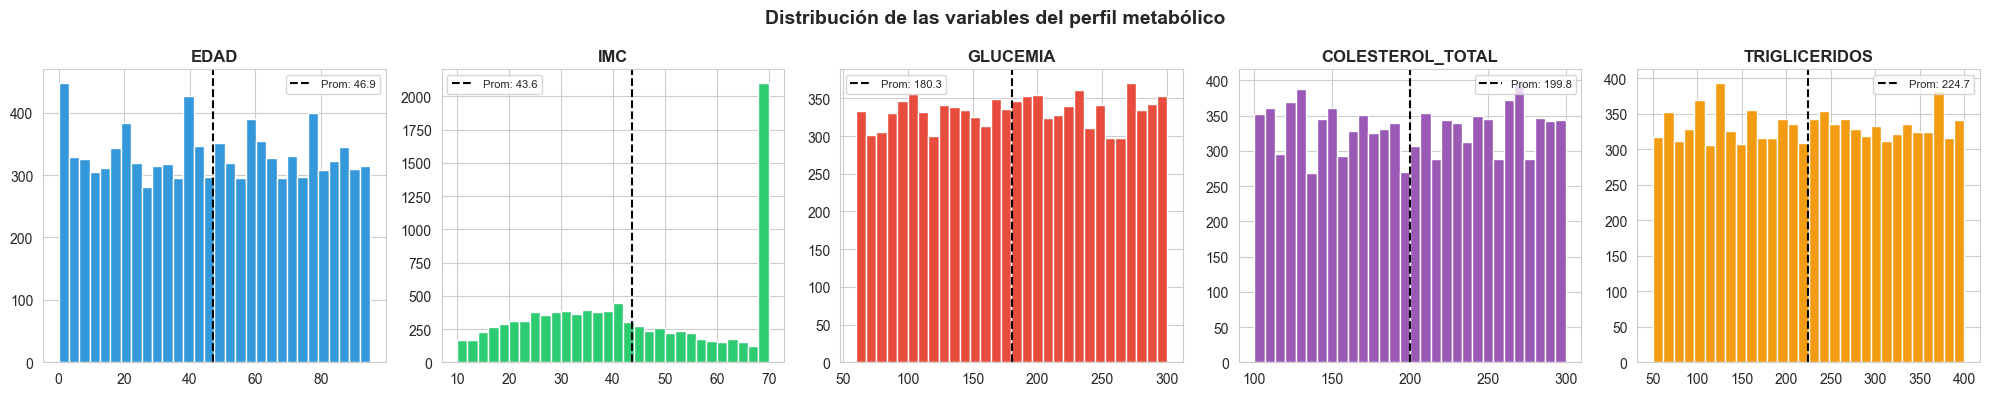

In [20]:
# ── Histogramas de las variables del perfil metabólico ───────
features = ['EDAD', 'IMC', 'GLUCEMIA', 'COLESTEROL_TOTAL', 'TRIGLICERIDOS']
colores  = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6', '#f39c12']

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, var, color in zip(axes, features, colores):
    ax.hist(df[var], bins=30, color=color, edgecolor='white')   # histograma
    ax.axvline(df[var].mean(), color='black', linestyle='--',     # línea del promedio
               label=f"Prom: {df[var].mean():.1f}")
    ax.set_title(var, fontweight='bold')
    ax.legend(fontsize=8)

plt.suptitle('Distribución de las variables del perfil metabólico', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

💡 **¿Qué nos dice esto?**
- Edad, glucemia, colesterol y triglicéridos tienen histogramas casi **planos** (cada valor aparece más o menos la misma cantidad de veces). Con datos tan parejos, es difícil que aparezcan grupos naturales muy marcados.
- El IMC tiene una **barra muy alta en 70**: son los 1,956 pacientes con IMC imposible (mayor a 70) que recortamos a ese valor. Esto va a influir en los clusters.

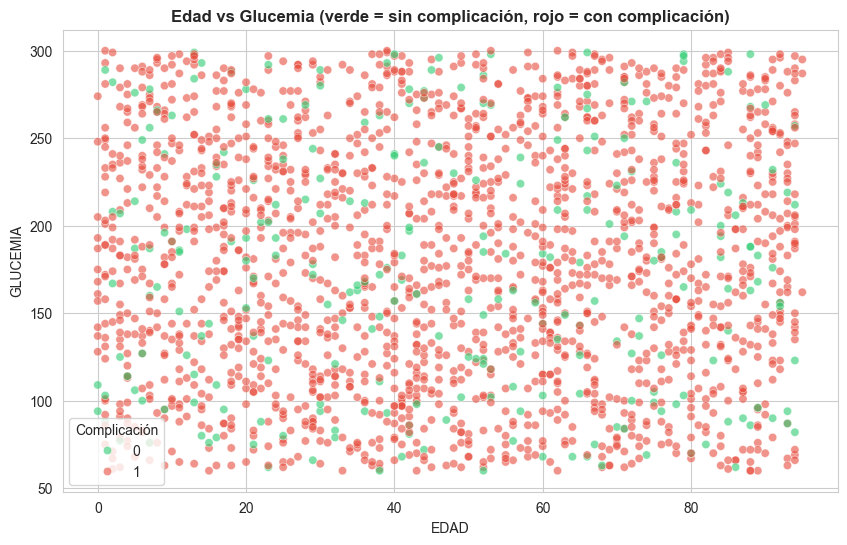

In [21]:
# ── Dispersión: EDAD vs GLUCEMIA, coloreado por complicación ─
# Usamos una muestra de 2,000 pacientes para que el gráfico se vea claro
muestra = df.sample(2000, random_state=SEMILLA)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=muestra, x='EDAD', y='GLUCEMIA',
                hue='TARGET_COMPLICACION', palette={0: '#2ecc71', 1: '#e74c3c'},
                alpha=0.6)
plt.title('Edad vs Glucemia (verde = sin complicación, rojo = con complicación)',
          fontweight='bold')
plt.legend(title='Complicación')
plt.show()

💡 **¿Qué nos dice esto?** Los puntos rojos (con complicación) y verdes (sin complicación) están **mezclados en todo el gráfico**. No hay una zona de edad o glucemia donde se concentren las complicaciones. Esto coincide con lo que vimos en la regresión logística y el árbol de decisión.

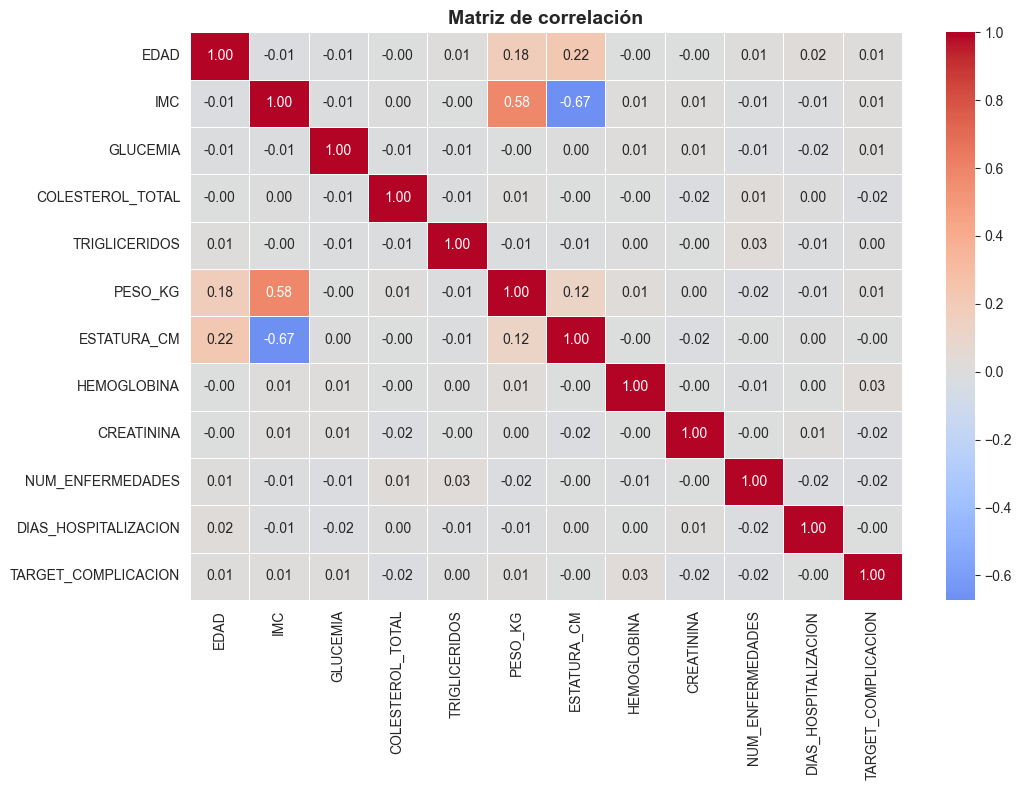

In [22]:
# ── Mapa de calor de correlaciones ───────────────────────────
# Correlación: 1 = suben juntas | -1 = una sube y la otra baja | 0 = sin relación
vars_corr = features + ['PESO_KG', 'ESTATURA_CM', 'HEMOGLOBINA', 'CREATININA',
                        'NUM_ENFERMEDADES', 'DIAS_HOSPITALIZACION', 'TARGET_COMPLICACION']

plt.figure(figsize=(11, 8))
sns.heatmap(df[vars_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5)
plt.title('Matriz de correlación', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

💡 **¿Qué nos dice esto?** Casi todas las correlaciones son **≈ 0**: las variables no se relacionan entre sí. La única relación clara es entre **IMC, peso y estatura**, lógico porque el IMC se calcula con ellas. Por eso usamos solo el IMC y no las tres. `TARGET_COMPLICACION` tampoco se relaciona con ninguna variable clínica.

---
## Paso 4: Preprocesamiento (selección y escalado)

🎯 **Qué hacemos:**
1. **Elegimos las variables** que usará K-Means: el perfil metabólico del paciente.
2. **Las escalamos**: K-Means mide distancias, y si una variable tiene números grandes (triglicéridos hasta 400) y otra pequeños (IMC hasta 70), la grande "pesaría más". El `StandardScaler` las deja a todas con **promedio 0 y desviación 1**.

| Variable elegida | Por qué |
|---|---|
| `EDAD` | factor de riesgo general |
| `IMC` | resume peso y estatura (por eso no usamos esas dos) |
| `GLUCEMIA` | azúcar en sangre (diabetes) |
| `COLESTEROL_TOTAL` | riesgo cardiovascular |
| `TRIGLICERIDOS` | riesgo cardiovascular / metabólico |

❌ **No usamos** datos personales (nombre, CI, teléfono) ni `COMPLICACIONES`, que la guardamos para comparar al final.

In [23]:
# ── Selección de variables para el clustering ────────────────
features = ['EDAD', 'IMC', 'GLUCEMIA', 'COLESTEROL_TOTAL', 'TRIGLICERIDOS']
X = df[features].copy()

print(f"Matriz para K-Means: {X.shape[0]:,} pacientes × {X.shape[1]} variables")
print(f"Nulos restantes: {X.isnull().sum().sum()}")

Matriz para K-Means: 10,000 pacientes × 5 variables
Nulos restantes: 0


In [24]:
# ── Escalado con StandardScaler ──────────────────────────────
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)   # aprende promedio/desviación y transforma

# Comprobamos: después del escalado, promedio ≈ 0 y desviación ≈ 1
comparacion = pd.DataFrame({
    'Promedio ANTES':    X.mean().round(1),
    'Desviación ANTES':  X.std().round(1),
    'Promedio DESPUÉS':  X_scaled.mean(axis=0).round(2),
    'Desviación DESPUÉS': X_scaled.std(axis=0).round(2),
}, index=features)
comparacion

,Promedio ANTES,Desviación ANTES,Promedio DESPUÉS,Desviación DESPUÉS
EDAD,46.9,27.5,0.0,1.0
IMC,43.6,18.7,-0.0,1.0
GLUCEMIA,180.3,69.1,0.0,1.0
COLESTEROL_TOTAL,199.8,58.4,0.0,1.0
TRIGLICERIDOS,224.7,101.3,0.0,1.0


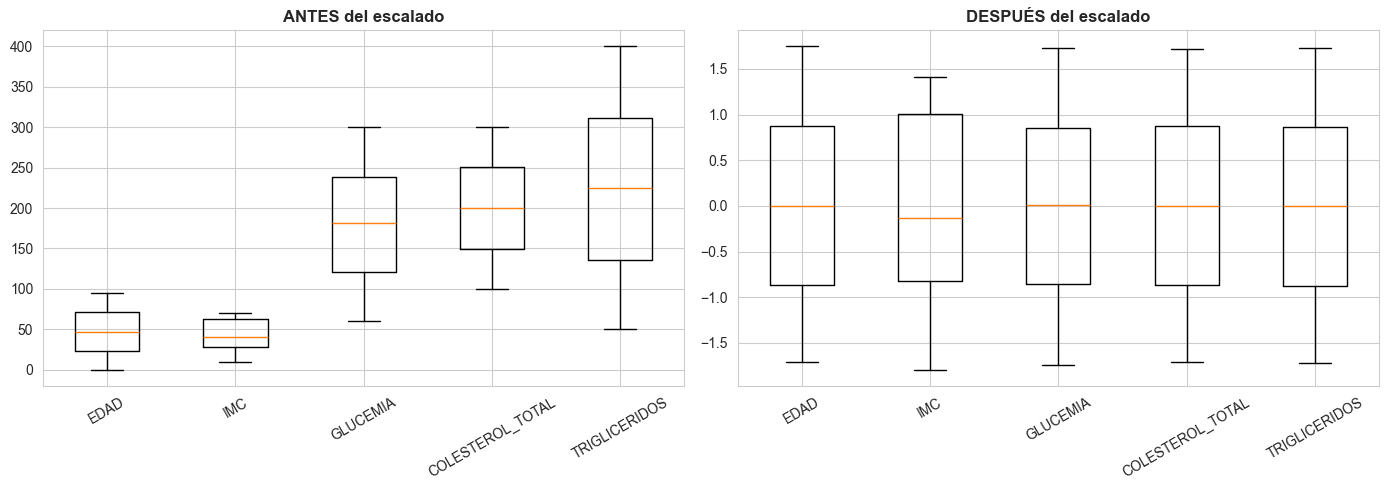

In [25]:
# ── Efecto visual del escalado ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Antes: cada variable en su propia escala
axes[0].boxplot([X[f] for f in features])
axes[0].set_xticklabels(features)
axes[0].set_title('ANTES del escalado', fontweight='bold')
axes[0].tick_params(axis='x', rotation=30)

# Después: todas en la misma escala
axes[1].boxplot([X_scaled[:, i] for i in range(len(features))])
axes[1].set_xticklabels(features)
axes[1].set_title('DESPUÉS del escalado', fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

💡 **¿Qué nos dice esto?** Antes del escalado, triglicéridos y glucemia tenían números mucho más grandes que el IMC o la edad. Después, **todas tienen promedio 0 y desviación 1**, así que K-Means les da el mismo peso a las 5.

---
## Paso 5: Implementación de K-Means

🎯 **Qué hacemos:** K-Means necesita que le digamos **cuántos grupos (K)** formar. Para elegir K usamos dos métodos:

- **Método del Codo:** calcula la "inercia" (WCSS, qué tan dispersos están los puntos dentro de cada grupo) para varios K. Buscamos el punto donde la curva **deja de bajar fuerte**, el "codo".
- **Silhouette Score:** mide de -1 a 1 qué tan bien separado está cada grupo. **Más alto = mejor.** Como referencia: > 0.5 bueno, 0.25–0.5 aceptable, < 0.25 grupos débiles.

In [17]:
# ── Método del Codo + Silhouette para K = 2 a 10 ─────────────
k_range = range(2, 11)
wcss = []               # inercia de cada K
silhouette_scores = []  # silhouette de cada K

for k in k_range:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
    etiquetas = modelo.fit_predict(X_scaled)
    wcss.append(modelo.inertia_)
    # Silhouette sobre una muestra de 5,000 para que sea rápido
    silhouette_scores.append(
        silhouette_score(X_scaled, etiquetas, sample_size=5000, random_state=SEMILLA))
    print(f"K={k:2d} | WCSS={modelo.inertia_:>10,.0f} | Silhouette={silhouette_scores[-1]:.3f}")

K= 2 | WCSS=    42,429 | Silhouette=0.148
K= 3 | WCSS=    37,385 | Silhouette=0.148
K= 4 | WCSS=    34,053 | Silhouette=0.148
K= 5 | WCSS=    31,098 | Silhouette=0.150
K= 6 | WCSS=    28,760 | Silhouette=0.156
K= 7 | WCSS=    26,965 | Silhouette=0.155
K= 8 | WCSS=    25,311 | Silhouette=0.163
K= 9 | WCSS=    23,715 | Silhouette=0.167
K=10 | WCSS=    22,384 | Silhouette=0.172


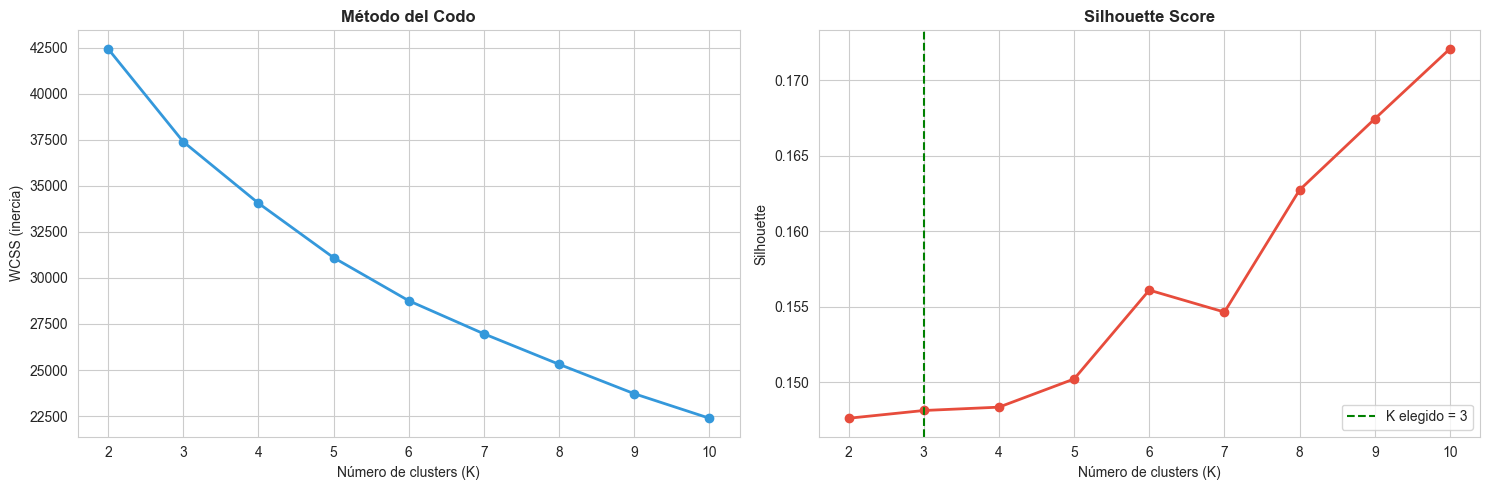

 K con Silhouette más alto: 10 (0.172)
 Silhouette con K=3: 0.148  (diferencia muy pequeña)


In [19]:
# ── Gráficos: Codo y Silhouette ──────────────────────────────
mejor_k = list(k_range)[int(np.argmax(silhouette_scores))]   # K con mayor silhouette

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Codo
axes[0].plot(list(k_range), wcss, 'o-', color='#3498db', linewidth=2)
axes[0].set_title('Método del Codo', fontweight='bold')
axes[0].set_xlabel('Número de clusters (K)')
axes[0].set_ylabel('WCSS (inercia)')

# Silhouette
axes[1].plot(list(k_range), silhouette_scores, 'o-', color='#e74c3c', linewidth=2)
axes[1].axvline(3, color='green', linestyle='--', label='K elegido = 3')
axes[1].set_title('Silhouette Score', fontweight='bold')
axes[1].set_xlabel('Número de clusters (K)')
axes[1].set_ylabel('Silhouette')
axes[1].legend()

plt.tight_layout()
plt.show()
print(f" K con Silhouette más alto: {mejor_k} ({max(silhouette_scores):.3f})")
print(f" Silhouette con K=3: {silhouette_scores[1]:.3f}  (diferencia muy pequeña)")

💡 **¿Qué nos dice esto?**
- **Codo:** la curva baja de forma suave y **no tiene un codo claro**. La mayor caída está entre K=2 y K=3.
- **Silhouette:** se mantiene casi igual (**≈ 0.15**) para todos los K. Sube un poco con K=10, pero eso pasa porque con muchos grupos cada uno es más pequeño, no porque los grupos sean mejores.
- **Decisión: K = 3.** El silhouette es prácticamente el mismo que con K más grandes, y 3 grupos son mucho **más fáciles de interpretar** y explicar.

### Entrenar el modelo final

🎯 **Qué hacemos:** entrenamos K-Means con el K elegido y le asignamos a cada paciente el número de su grupo (cluster).

In [26]:
# ── Entrenar K-Means con el K elegido ────────────────────────
K_OPTIMO = 3   # elegido con el Silhouette y el codo (ver gráficos de arriba)

kmeans = KMeans(n_clusters=K_OPTIMO, n_init=10, random_state=SEMILLA)
df['CLUSTER'] = kmeans.fit_predict(X_scaled)   # grupo de cada paciente: 0, 1 o 2

print("👥 Pacientes por cluster:")
print(df['CLUSTER'].value_counts().sort_index())

👥 Pacientes por cluster:
CLUSTER
0    3329
1    3278
2    3393
Name: count, dtype: int64


###  Visualización de los Clusters

🎯 **Qué hacemos:** como tenemos 5 variables y solo podemos dibujar 2, graficamos los pares de variables más importantes con un color por cluster. La ✖ negra marca el **centro (centroide)** de cada grupo.

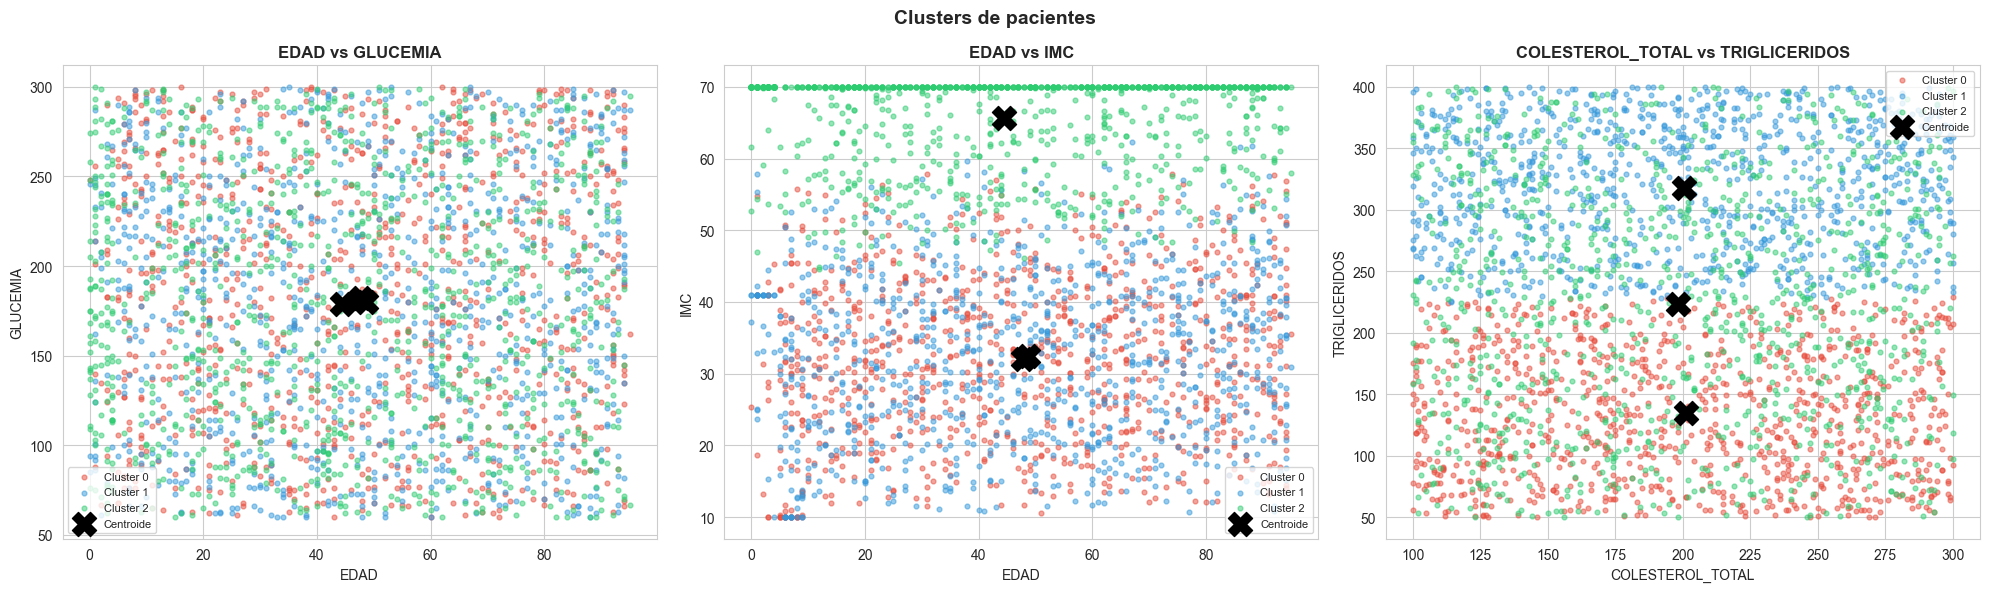

In [27]:
# ── Colores y centroides en la escala original ───────────────
COLORES = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']
# Los centroides están escalados → los "des-escalamos" para leerlos en unidades reales
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)

muestra = df.sample(3000, random_state=SEMILLA)   # muestra para que se vea claro
pares = [('EDAD', 'GLUCEMIA'), ('EDAD', 'IMC'), ('COLESTEROL_TOTAL', 'TRIGLICERIDOS')]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (vx, vy) in zip(axes, pares):
    for c in range(K_OPTIMO):
        datos = muestra[muestra['CLUSTER'] == c]
        ax.scatter(datos[vx], datos[vy], s=12, alpha=0.5,
                   color=COLORES[c], label=f'Cluster {c}')
    ax.scatter(centroides[vx], centroides[vy], marker='X', s=300,
               color='black', label='Centroide')
    ax.set_xlabel(vx); ax.set_ylabel(vy)
    ax.set_title(f'{vx} vs {vy}', fontweight='bold')
    ax.legend(fontsize=8)

plt.suptitle('Clusters de pacientes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

💡 **¿Qué nos dice esto?**
- En **Edad vs Glucemia** los colores están mezclados: estas variables **no separan** los grupos.
- En **Edad vs IMC** se ve un grupo arriba (verde) con **IMC extremo** (la línea en 70 son los valores recortados).
- En **Colesterol vs Triglicéridos** los grupos rojo y azul se separan por **triglicéridos bajos vs altos**.

Es decir, K-Means agrupó a los pacientes principalmente por **IMC y triglicéridos**.

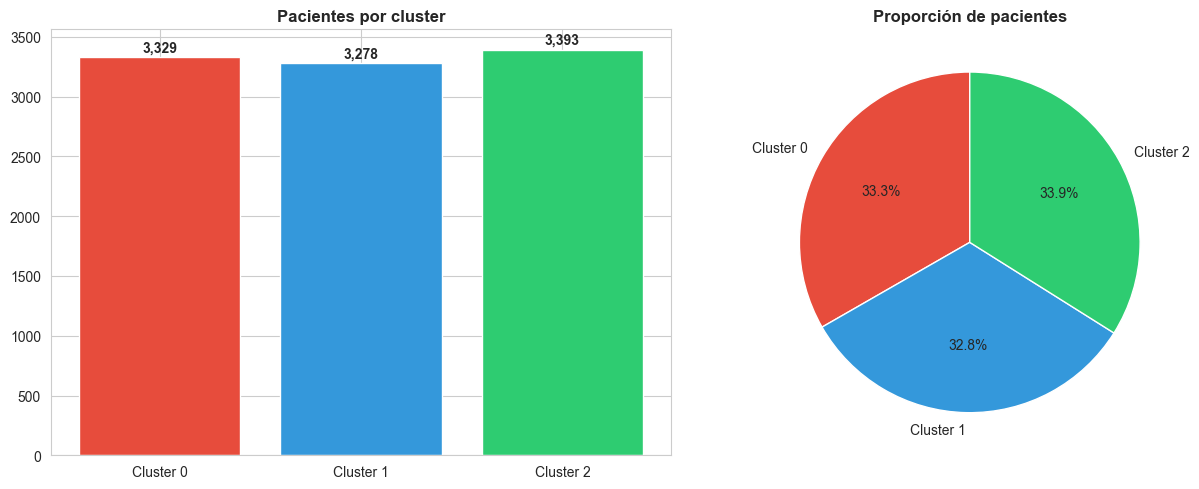

In [28]:
# ── Tamaño de cada cluster ───────────────────────────────────
conteo = df['CLUSTER'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar([f'Cluster {i}' for i in conteo.index], conteo.values,
            color=COLORES[:K_OPTIMO])
axes[0].set_title('Pacientes por cluster', fontweight='bold')
for i, v in enumerate(conteo.values):
    axes[0].text(i, v + 50, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(conteo.values, labels=[f'Cluster {i}' for i in conteo.index],
            colors=COLORES[:K_OPTIMO], autopct='%1.1f%%', startangle=90)
axes[1].set_title('Proporción de pacientes', fontweight='bold')

plt.tight_layout()
plt.show()

💡 **¿Qué nos dice esto?** Los 3 grupos tienen un tamaño muy parecido (≈ 3,300 pacientes cada uno, ~33 %). Ningún grupo es demasiado pequeño, así que todos son útiles para analizar.

---
##  Paso 6: Perfilado de Clusters

🎯 **Qué hacemos:** describimos cada grupo con sus **promedios** para darle un nombre fácil de entender. Luego respondemos la pregunta del proyecto: **¿algún grupo tiene más complicaciones?**

In [30]:
# ── Promedio de cada variable por cluster ────────────────────
perfil = df.groupby('CLUSTER')[features].mean().round(1)
perfil['N_PACIENTES'] = df['CLUSTER'].value_counts().sort_index()
perfil

,EDAD,IMC,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,N_PACIENTES
CLUSTER,,,,,,
0,47.7,32.1,182.0,201.0,134.3,3329
1,48.7,32.4,180.2,200.3,318.0,3278
2,44.5,65.6,178.8,198.2,223.3,3393


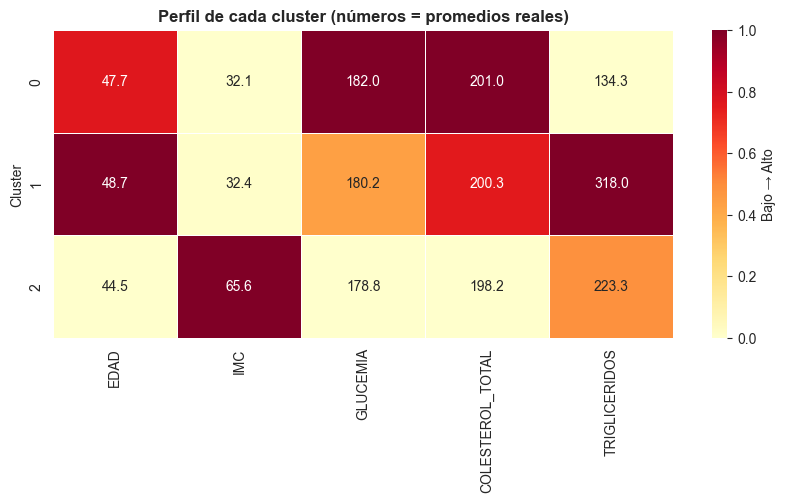

In [31]:
# ── Mapa de calor del perfil (0 = más bajo, 1 = más alto) ────
# Normalizamos cada columna para comparar en la misma escala visual
perfil_norm = (perfil[features] - perfil[features].min()) / \
              (perfil[features].max() - perfil[features].min())

plt.figure(figsize=(10, 4))
sns.heatmap(perfil_norm, annot=perfil[features], fmt='.1f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Bajo → Alto'})
plt.title('Perfil de cada cluster (números = promedios reales)', fontweight='bold')
plt.ylabel('Cluster')
plt.show()

💡 **¿Qué nos dice esto?** Edad, glucemia y colesterol son **casi iguales** en los 3 clusters. Las diferencias reales están en:

| Cluster | Lo que lo distingue | Nombre sugerido |
|---|---|---|
| **0** | Triglicéridos **bajos** (≈ 134) e IMC ≈ 32 | 🟥 *Triglicéridos bajos* |
| **1** | Triglicéridos **altos** (≈ 318) e IMC ≈ 32 | 🟦 *Triglicéridos altos* |
| **2** | IMC **extremo** (≈ 66) | 🟩 *IMC extremo* |

⚠️ El Cluster 2 reúne sobre todo a los pacientes con IMC mayor a 70 que vimos en el Paso 3. Más que un perfil médico real, este grupo refleja un **problema de calidad de datos** (pesos y estaturas que no coinciden).

In [32]:
# ── ¿Qué cluster tiene más complicaciones? ───────────────────
comparacion = df.groupby('CLUSTER').agg(
    Pacientes=('TARGET_COMPLICACION', 'size'),
    Tasa_complicacion=('TARGET_COMPLICACION', lambda s: round(s.mean() * 100, 2)),
    Dias_hosp_prom=('DIAS_HOSPITALIZACION', 'mean'),
    Enfermedades_prom=('NUM_ENFERMEDADES', 'mean'),
).round(2)
print(f"Tasa global de complicaciones: {tasa_global:.2f}%\n")
comparacion

Tasa global de complicaciones: 87.82%



,Pacientes,Tasa_complicacion,Dias_hosp_prom,Enfermedades_prom
CLUSTER,,,,
0,3329,87.53,1.83,2.49
1,3278,87.74,1.78,2.54
2,3393,88.18,1.77,2.52


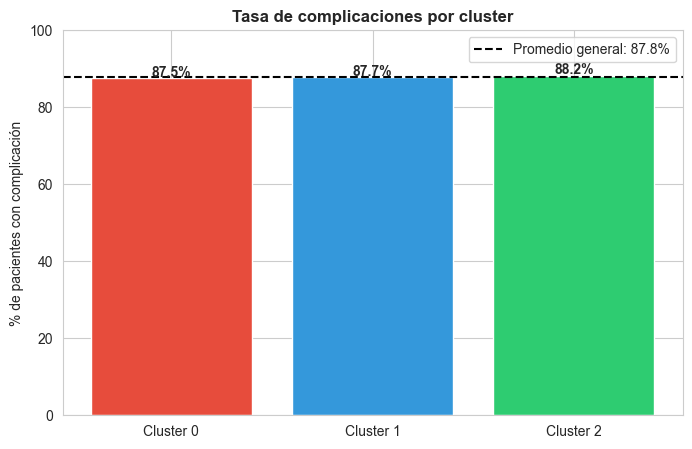

COMPLICACIONES,Embolia,Fallo Multiorgánico,Hemorragia,Infeccion Nosocomial,Ninguna,Reaccion Adversa,Sepsis
CLUSTER,,,,,,,
0,12.7,12.9,14.7,16.0,12.5,17.1,14.1
1,14.1,12.0,14.3,16.8,12.3,17.3,13.2
2,13.5,12.1,15.6,16.1,11.8,16.3,14.6


In [34]:
# ── Gráfico: tasa de complicación por cluster ────────────────
plt.figure(figsize=(8, 5))
barras = plt.bar([f'Cluster {i}' for i in comparacion.index],
                 comparacion['Tasa_complicacion'], color=COLORES[:K_OPTIMO])
plt.axhline(tasa_global, color='black', linestyle='--',
            label=f'Promedio general: {tasa_global:.1f}%')
for b in barras:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5,
             f'{b.get_height():.1f}%', ha='center', fontweight='bold')
plt.ylim(0, 100)
plt.ylabel('% de pacientes con complicación')
plt.title('Tasa de complicaciones por cluster', fontweight='bold')
plt.legend()
plt.show()

# Tipo de complicación dentro de cada cluster (% por fila)
pd.crosstab(df['CLUSTER'], df['COMPLICACIONES'], normalize='index').mul(100).round(1)

💡 **¿Qué nos dice esto?** Esta es la respuesta a la pregunta del proyecto: los 3 clusters tienen **casi la misma tasa de complicaciones** (87.5 %, 87.7 % y 88.2 %), igual al promedio general (87.8 %). Los tipos de complicación también se reparten casi igual en cada grupo.

Tener triglicéridos altos o un IMC muy alto **no se asocia con más complicaciones** en este dataset.

In [35]:
# ── Etiquetas descriptivas de cada cluster ───────────────────
# Comparamos el promedio del cluster con el promedio general.
# Solo marcamos una variable si se aleja bastante (más de 0.25 desviaciones);
# las diferencias pequeñas se consideran "normales"
prom_general = df[features].mean()

desv_general = df[features].std()

def describir(fila):
    partes = []
    for var in features:
        # Cuántas desviaciones se aleja el cluster del promedio general
        z = (fila[var] - prom_general[var]) / desv_general[var]
        if z > 0.25:
            partes.append(f"{var} ALTO ⬆")
        elif z < -0.25:
            partes.append(f"{var} BAJO ⬇")
    # Si ninguna variable se aleja, el cluster es "promedio"
    return ', '.join(partes) if partes else 'similar al promedio en todo'


for c, fila in perfil.iterrows():
    print(f"🔹 Cluster {c} ({int(fila['N_PACIENTES']):,} pacientes): {describir(fila)}")

🔹 Cluster 0 (3,329 pacientes): IMC BAJO ⬇, TRIGLICERIDOS BAJO ⬇
🔹 Cluster 1 (3,278 pacientes): IMC BAJO ⬇, TRIGLICERIDOS ALTO ⬆
🔹 Cluster 2 (3,393 pacientes): IMC ALTO ⬆


💡 **¿Qué nos dice esto?** La descripción automática confirma la tabla: cada cluster se diferencia solo por **una o dos variables** (IMC y/o triglicéridos). En edad, glucemia y colesterol, los tres grupos son parecidos al promedio general.

---
## Paso 7: Evaluación del Modelo

🎯 **Qué hacemos:** medimos la calidad final de los grupos con dos métricas:

- **Silhouette Score** (-1 a 1): qué tan separados están los grupos. Más alto = mejor.
- **Inercia (WCSS):** qué tan compactos son los grupos. Más bajo = mejor (sirve para comparar entre K, no tiene un "valor bueno" fijo).

In [39]:
# ── Métricas del modelo final ────────────────────────────────
sil_final = silhouette_score(X_scaled, df['CLUSTER'], sample_size=5000, random_state=SEMILLA)

print(" EVALUACIÓN DEL MODELO K-MEANS")
print("=" * 45)
print(f"  Número de clusters (K): {K_OPTIMO}")
print(f"  Silhouette Score:       {sil_final:.3f}")
print(f"  Inercia (WCSS):         {kmeans.inertia_:,.0f}")
print("=" * 45)

if sil_final > 0.5:
    print("✅ Grupos bien separados")
elif sil_final > 0.25:
    print("🟡 Grupos con separación aceptable")
else:
    print("🔴 Grupos débiles: los pacientes no forman grupos muy diferenciados")

 EVALUACIÓN DEL MODELO K-MEANS
  Número de clusters (K): 3
  Silhouette Score:       0.148
  Inercia (WCSS):         37,385
🔴 Grupos débiles: los pacientes no forman grupos muy diferenciados


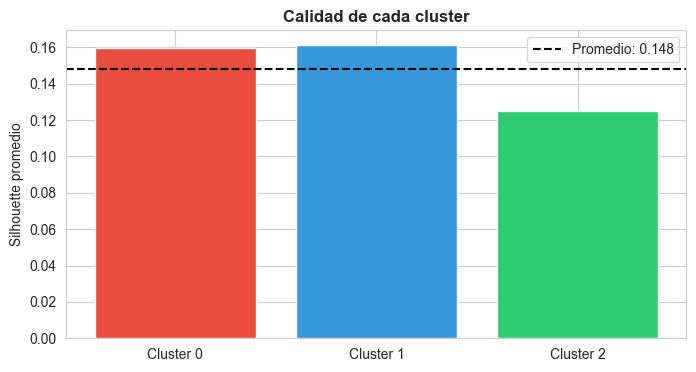

In [37]:
# ── Silhouette de cada cluster ───────────────────────────────
from sklearn.metrics import silhouette_samples

# Calculamos el silhouette de cada paciente (sobre una muestra) y promediamos por cluster
idx = df.sample(5000, random_state=SEMILLA).index
sil_ind = silhouette_samples(X_scaled[idx], df.loc[idx, 'CLUSTER'])
sil_cluster = pd.Series(sil_ind).groupby(df.loc[idx, 'CLUSTER'].values).mean()

plt.figure(figsize=(8, 4))
plt.bar([f'Cluster {i}' for i in sil_cluster.index], sil_cluster.values,
        color=COLORES[:K_OPTIMO])
plt.axhline(sil_final, color='black', linestyle='--', label=f'Promedio: {sil_final:.3f}')
plt.ylabel('Silhouette promedio')
plt.title('Calidad de cada cluster', fontweight='bold')
plt.legend()
plt.show()

💡 **¿Qué nos dice esto?**
- El **Silhouette de 0.148** es **bajo** (menor a 0.25): los grupos existen, pero se tocan y se mezclan entre sí. No son grupos naturales muy separados.
- Los 3 clusters tienen una calidad parecida, ninguno es mucho peor.
- Esto **no es un error del código**: pasa porque las variables del dataset no tienen relación entre sí (lo vimos en el mapa de correlaciones). Es el mismo motivo por el que la regresión logística y el árbol de decisión no lograron superar la exactitud base (87.8 %).

---
##  Paso 8: Conclusiones

1. **Se formaron 3 perfiles de pacientes** según su perfil metabólico: *triglicéridos bajos*, *triglicéridos altos* e *IMC extremo*. Las variables que más separan a los grupos son el **IMC** y los **triglicéridos**. El grupo de IMC extremo se debe en gran parte a datos poco realistas (19.6 % de pacientes con IMC mayor a 70).
2. **La calidad de los grupos es baja** (Silhouette = 0.148): los pacientes no forman grupos naturales bien diferenciados, porque las variables clínicas casi no se relacionan entre sí.
3. **Ningún cluster tiene más complicaciones que otro** (todos ≈ 88 %). El perfil metabólico **no explica** quién tiene complicaciones en este dataset, lo que coincide con los resultados de la regresión logística y el árbol de decisión.
4. **Recomendación:** para encontrar grupos de riesgo útiles harían falta variables con más relación con las complicaciones (tipo de cirugía, duración de la estancia, procedimientos invasivos, etc.) o datos clínicos reales, ya que esta base parece generada automáticamente.

In [38]:
# ── Resumen final ────────────────────────────────────────────
print("🎓 RESUMEN — K-Means: Perfiles de Pacientes")
print("=" * 50)
print(f"  Pacientes analizados:   {len(df):,}")
print(f"  Variables usadas:       {', '.join(features)}")
print(f"  K elegido:              {K_OPTIMO}")
print(f"  Silhouette final:       {sil_final:.3f}")
print(f"  Tasa global compl.:     {tasa_global:.2f}%")
for c, tasa in comparacion['Tasa_complicacion'].items():
    print(f"  Cluster {c}: {comparacion.loc[c, 'Pacientes']:>5,} pacientes | {tasa:.2f}% con complicación")
print("=" * 50)

🎓 RESUMEN — K-Means: Perfiles de Pacientes
  Pacientes analizados:   10,000
  Variables usadas:       EDAD, IMC, GLUCEMIA, COLESTEROL_TOTAL, TRIGLICERIDOS
  K elegido:              3
  Silhouette final:       0.148
  Tasa global compl.:     87.82%
  Cluster 0: 3,329 pacientes | 87.53% con complicación
  Cluster 1: 3,278 pacientes | 87.74% con complicación
  Cluster 2: 3,393 pacientes | 88.18% con complicación
